<a href="https://colab.research.google.com/github/kalinapeterson12/Data-201-Labs/blob/main/Assignments/Kalina_Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Homework

### Installing the Data

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [3]:
hitters = load_data('Hitters') # Load data
print('Original shape:', hitters.shape) # dimensions of the data
display(hitters.head()) # first 6 observations
print('Missing values:')
print(hitters.isna().sum().sort_values()) #finding number of na's

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [4]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary') # dropping the salary column because that is what we are trying to predict. Cannot give the model the answers
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


## Part 1: Experiment with a

Using the same training and test sets from the lab, fit three Lasso models with:
alpha_values = [0.1, 10, 100]
For each model, report:
 - Training RMSE
 - Test RMSE
 -  Number of nonzero coefficients

 Create a table comparing the three models.

 **Questions:**
 1. As α increases, what happens to the number of retained predictors?
2. Does a smaller number of predictors always lead to a lower test RMSE?

In [5]:
# Defining the Necessary functions
# ----------------------------------
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols), #scaling the data
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols) # encoding categorical variables
            ])


def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)), # We want RMSE and R sqaured because we are predicting a numerical, not categorical variable
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


In [6]:
# Experimenting with different a's in Lasso TRAINING
# -------------------------------------------
alpha_examples = [0.1, 10, 100]
rows = []

for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])

        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        train_preds = pipe.predict(X_train)
        test_preds = pipe.predict(X_test)

       #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Training RMSE': np.sqrt(mean_squared_error(y_train, train_preds)),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, test_preds))
        })

alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))


,alpha,Nonzero coefficients,Training RMSE,Test RMSE
0,0.1,19,289.38,356.83
1,10.0,9,303.10,381.84
2,100.0,5,341.39,395.12


As $a$ increases, the number of retained predictors decreases. This is because the model is becoming more strict and will remove more variables because they don't contribute to the model or are highly correlated with another predictor.

No, a smaller number of predictors does not always lead to a lower RMSE. In fact, with this case our test RMSE was 324.21 with 12 predictors, but there was a higher error (389.62) with only 3 predictors ($a$ of 100).

## Part 2: Visualize and Interpret

Create a graph showing α versus Test RMSE for the three models.

**Questions:**
1. Which α produces the lowest test RMSE among the three values?
2. Which α appears to cause the most underfitting? Explain using bias.
3. Why might a model with higher training RMSE produce lower test RMSE?

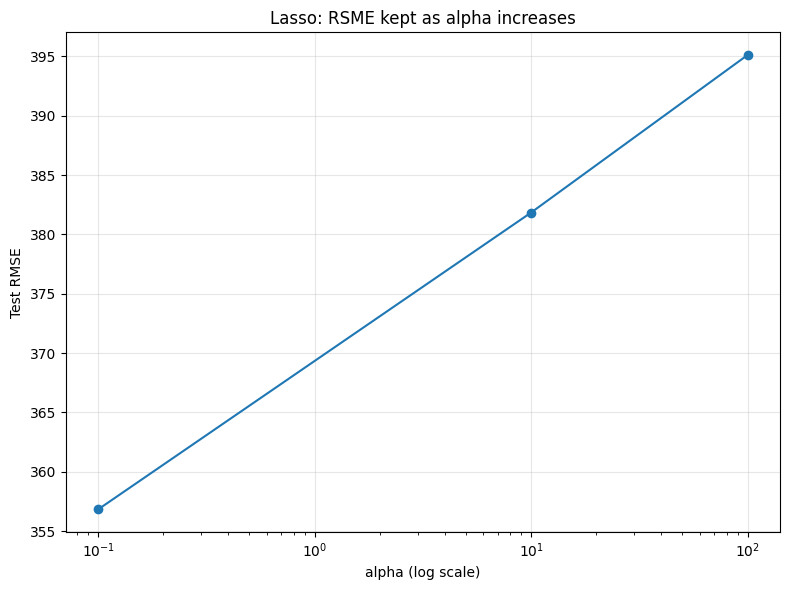

In [7]:
# Altered class code by changing the figsize, removing the for loop, changing the y variable from the number of predictors
# to the standard error, and pulling values directly from the alpha_table

fig, ax = plt.subplots(figsize=(8, 6))
ax.semilogx(alpha_table['alpha'], alpha_table['Test RMSE'], marker='o')
ax.set_title(f'{kind}: RSME kept as alpha increases')
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Test RMSE')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()





1. An $a$ of .1 produced the lowest standard error among the three values
2.  An $a$ of 0.1 is most likely to underfit. In underfitting, there are not enough predictors and the model performs poorly on both training and testing data. In bias, the model sees nothing as important and underfits. The bias variance tradeoff is as you add predictors the model learns well, but more noise is added and the testing data performs worse (this is the case of overfitting). Smaller alphas are more likely to have bias, cut more predictors, and thus underfit. So, 0.1 is more likely to underfit.

3. High variance, overfitting, would cause the model to perform very well on the training data but fail on the testing data. When overfitting, the model sees everything as important and is extremely flexible. However, it learns the training data too well and fails to perform on the testing data because all the model has done is memorized every pattern and aspect of the training data, rather than actually learning from it. Thus, high variance could lead to a low training error but high testing error.


## Part 3: Model Interpretation

Using your results from Part 1:
1. Identify two predictors that Lasso sets to zero at α = 100.
2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.
3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance

In [8]:
# Cross Validation so I can extract features without error messages
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)

lasso_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()),
              ('model', Lasso(max_iter=30000))]),
    {'model__alpha': np.logspace(-2, 4, 40)},
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print('Best lasso alpha:', lasso_grid.best_params_['model__alpha'])
print('Best lasso CV RMSE:', np.sqrt(-lasso_grid.best_score_))

Best lasso alpha: 24.244620170823307
Best lasso CV RMSE: 349.49427101392234


In [9]:
# altered class
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Lasso': pipe.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,Lasso
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


1. Two features that Lasso sets to zero are num_Assists (the number of assists) and num_Runs (the number of runs).

2. No, predictors can be set to zero because they are correlated with another variable that contributes equally or more so to determining the player's salary.

3. If the two models have similar RMSE, you should select the model with fewer predictors. This makes the model easier to interpret, as there are less factors being used to determine the salary. And, since the RSME is similar between the two models the predictive performance is not affected by using fewer predictors. When model performence is not affected the simpler model is always better.

## Part 4: Choosing the Right Regression Model

For each scenario, choose Ridge (L2), Lasso (L1), Ordinary Linear Regression, or Not Sure.
Explain your choice in 2-3 sentences, considering the number of predictors, model complexity,
interpretability, and potential overfitting.

Reminder: There is not always enough information to determine which model will perform best. Consider when cross-validation would be necessary to make a decision.

- **Scenario A:** A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.
   
     * Lasso is the best option in this scenario. If the researcher is aiming to eliminate predictors so only a few features are kept in the model, then lasso is needed to reduce correlated predictors (or simply predictors that don't contribute to the model) to zero.

- **Scenario B:** A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

    * If many of the predictors are correlated and the company believes that they contain useful information then Ridge is the best option. Ridge won't eliminate predictors, and it will share the weight between correlated variables.

- **Scenario C:** A researcher has 10,000 observations and only three predictors. The relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

    * In this scenario, Ordinary Linear Regression is the best option. With fewer predictors and a linear relationship this simpler model will perform well. This model is easier to interpret and there is very low risk of overfitting (the larger concern would likely be underfitting).

- **Scenario D:** A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.

    * In this scenario there is not enough information to clearly determine which model would be best. If many of the predictors are useful we would likely prefer Ridge, if not we would want Lasso. Each of those models handles predictor correlations differently. However, if the company wants the most accurate predictions then cross validation should be performed on the selected to ensure the best alpha is chosen. Assuming we have the CPU, the ideal would be to test all three of these models and to perform cross validation to find the best model-alpha combination for this dataset.

